# 04. Geographic Validation of Regional Resilience and Cumulative Shortfalls

**Purpose:** Strengthen the *evaluation* of the cumulative employment-shortfall model without selecting a conveniently favorable outcome or leaking information from the pandemic period.

### Design

- Retain the original 46-month positive cumulative shortfall as the prespecified long-run target; compare it with 12- and 24-month outcomes as sensitivity analyses. Also assess resistance, recovery gain, and persistence using **the same nested geographic validation**.
- Compare a training-median benchmark with Ridge on the original scale, log1p-transformed Ridge, and (optionally) nonlinear histogram gradient boosting with robust absolute-error loss.
- Compare core socioeconomic and size features, pre-pandemic industry structure, and their combination.
- Use nested geographic validation: hold out one Census division at a time; tune hyperparameters and choose the model *using the other divisions only*. Missing-value screening, imputation and scaling occur inside each training fold.
- Evaluate raw-scale MAE, RMSE, R² (pooled and fold-level), out-of-sample R² vs the **training-division mean**, bias, and MAE skill versus both the training-mean and training-median baselines. Report pooled and division-level scores. A failed benchmark is an informative result—not grounds to substitute test-driven specifications.
- Optional: use signed (unclipped) 46-month gaps to test sensitivity to treating months above the counterfactual as an offset to earlier deficits.

**Full-run settings in this package:** Leave-one-Census-division-out outer validation on **every** division, four inner grouped folds, median and training-mean benchmarks, Ridge/log-Ridge/HGB with the full standard grids, resistance/recovery/persistence/C12/C24/C46/signed C46, three historical-error stress targets, 1,000 clustered bootstrap resamples, employment-weighted sensitivity, coefficient and fit-failure auditing. Failures of optional model candidates are recorded; the training-only median benchmark remains available. This is a full setup, **not proof of successful national execution**.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, warnings, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from IPython.display import display

SEED = 2026
N_JOBS = 2  # full nested evaluation; limit concurrent model copies on 32-GB RAM
ENABLE_HGB = True  # include nonlinear boosting models
INCLUDE_SIGNED_46 = True  # include signed cumulative 46-month outcome
INCLUDE_HISTORICAL_STRESS = True  # evaluate three historical-error counterfactual targets
MAX_OUTER_DIVISIONS = 0  # ALL geographic divisions; ignore leftover smoke-test settings
MIN_FEATURE_COVERAGE = 0.50
BOOTSTRAP_REPS = 1000

ROOT = Path(os.environ['RL_PROJECT_ROOT']).resolve() if os.environ.get('RL_PROJECT_ROOT') else next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if
     (p/'data'/'processed'/'stage2_omb2018_resilience_outcomes.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find repository. Run notebook 03, or set RL_PROJECT_ROOT.')
PROC = ROOT/'data'/'processed'
OUT = ROOT/'output'
OUT.mkdir(parents=True, exist_ok=True)
PREFIX = 'stage2_geographic04_'
print('Repository:', ROOT)
print('N_JOBS:', N_JOBS, '| nonlinear HGB:', ENABLE_HGB, '| outer fold limit:', MAX_OUTER_DIVISIONS or 'all')
print('sklearn:', sklearn.__version__)

Repository: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience
N_JOBS: 2 | nonlinear HGB: True | outer fold limit: all
sklearn: 1.9.1


## 1. Load the established 2018 OMB inputs and verify provenance

The predictor list is an explicit whitelist: *no post-February-2020 values are features*. Stage 1 outputs and resilience outcomes are targets only. 

In [2]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(2*1024*1024),b''):
            h.update(b)
    return h.hexdigest()

p_path=PROC/'stage2_omb2018_pre2020_predictors.csv'
o_path=PROC/'stage2_omb2018_resilience_outcomes.csv'
if not p_path.exists() or not o_path.exists():
    raise FileNotFoundError('Run notebooks 02 and 03 to create the predictor and outcome CSVs.')
pmeta_path=OUT/'stage2_omb2018_predictors_manifest.json'
s1meta_path=OUT/'stage1_omb2018_manifest.json'
s2meta_path=OUT/'stage2_omb2018_modeling_manifest.json'
if not pmeta_path.exists() or not s1meta_path.exists() or not s2meta_path.exists():
    raise FileNotFoundError('Missing source manifests; rerun 01 and 02 in the 2018 OMB pipeline.')
pmeta=json.loads(pmeta_path.read_text())
s1meta=json.loads(s1meta_path.read_text())
s2meta=json.loads(s2meta_path.read_text())
if not s1meta.get('all_regions_included',False) :
    raise ValueError('Stage 1 partial sample is not suitable for national validation')
if not s2meta.get('stage1_complete',False) :
    raise ValueError('Stage 2 came from partial Stage 1 sample')
assert pmeta['geography_vintage']==s1meta['geography_vintage']=='2018-09', 'Geographic vintages do not match'
assert pmeta['information_cutoff']=='2020-02-29', 'Predictor information cutoff changed'
assert s1meta['model_training_cutoff']=='2019-06-01', 'Stage 1 model training cutoff changed'
assert sha256(p_path)==pmeta['predictors_sha256'], 'Predictor file changed since last manifest'
if sha256(o_path)!=s2meta.get('resilience_outcomes_sha256'):
    raise ValueError('Resilience outcomes differ from Stage 2 manifest; rerun notebook 03')
if sha256(PROC/'stage1_omb2018_observed_vs_counterfactual_2020_2023.csv') != s1meta['outcomes_sha256']:
    raise ValueError('Stage 1 monthly outcomes changed; rerun notebook 03')
monthly_source=PROC/'stage2_omb2018_monthly_gaps.csv'
if sha256(monthly_source)!=s2meta.get('monthly_gaps_sha256'):
    raise ValueError('Monthly gap file differs from Stage 2 manifest; rerun notebook 03')
if s2meta.get('historical_stress_outcomes_sha256') is not None:
    scenario_file=PROC/'stage1_omb2018_historical_stress_outcomes.csv'
    if not scenario_file.exists() or sha256(scenario_file)!=s2meta['historical_stress_outcomes_sha256']:
        raise ValueError('Historical stress source changed since Stage 2 manifest')

pred=pd.read_csv(p_path,dtype={'cbsa_code':'string'})
outcomes=pd.read_csv(o_path,dtype={'cbsa_code':'string'})
for df in (pred,outcomes):
    df['cbsa_code']=df['cbsa_code'].str.zfill(5)
    if df.cbsa_code.duplicated().any(): raise ValueError('Duplicate CBSA codes')
if len(pred)!=len(outcomes) or set(pred.cbsa_code)!=set(outcomes.cbsa_code):
    raise ValueError('Predictor/outcome CBSA samples differ')
df=outcomes.merge(pred,on='cbsa_code',how='inner',validate='one_to_one')
if df.geographic_group.isna().any():
    raise ValueError('Every CBSA must have a Census division grouping')
df.geographic_group=df.geographic_group.astype(str)
if df.geographic_group.nunique()<5:
    raise ValueError('At least five Census-division groups are required for nested group CV')

CORE=[
 'qcew2018to2019q2_growth', 'log_qcew2019q2_employment',
 'acs2018_bachelors_plus_share','acs2018_poverty_share',
 'acs2018_unemployment_share','acs2018_broadband_subscription_share'
]
INDUSTRY=sorted(c for c in pred.columns if c.startswith('qcew2019q2_share_naics_'))
INDUSTRY += [
    'qcew2019q2_private_share_all_covered',
    'qcew2019q2_private_goods_producing_share'
]
for name in CORE+INDUSTRY:
    if name not in df.columns:raise ValueError(f'Missing {name}; run corrected notebook 02')
if len(INDUSTRY)<12:
    raise ValueError('Industry features missing; rerun notebook 02 with the ownership-code fix')
FEATURE_SETS={'core':CORE,'industry':INDUSTRY,'combined':CORE+INDUSTRY}
for name,cols in FEATURE_SETS.items():
    for c in cols:
        df[c]=pd.to_numeric(df[c],errors='coerce')
        df.loc[~np.isfinite(df[c]),c]=np.nan
    print(name,':',len(cols),'eligible features before training-fold coverage filter')
print('CBSAs:',len(df),'Census divisions:',df.geographic_group.nunique())
display(df.geographic_group.value_counts().rename_axis('division').to_frame('CBSAs'))

core : 6 eligible features before training-fold coverage filter
industry : 21 eligible features before training-fold coverage filter
combined : 27 eligible features before training-fold coverage filter
CBSAs: 936 Census divisions: 10


,CBSAs
division,
East North Central,161
South Atlantic,151
West South Central,130
West North Central,120
East South Central,95
Mountain,93
Pacific,82
Middle Atlantic,66
New England,26


## 2. Describe target skew and compare horizons

The 12/24/46-month cumulative shortfalls are sums of nonnegative monthly percentage deficits. Dividing by horizon gives the average deficit per month for intuitive comparisons, but does not change predictive R². We retain all horizons and report their exact definitions.

Nested geographic CV will be repeated for all 46-month stress targets: ['2013_06', '2014_06', '2014_12']


,target,n,mean,median,p90,p99,max,skew
0,resistance,936,11.13,10.62,17.01,24.35,34.42,0.84
1,recovery,936,12.60,11.89,20.73,33.50,41.84,0.64
2,persistence,936,2.85,1.46,7.38,16.96,32.31,2.64
3,c12,936,83.01,78.82,132.48,211.92,338.75,1.10
4,c24,936,135.43,127.87,225.99,401.54,569.10,1.24
5,c46,936,202.33,177.76,368.56,752.56,1150.11,1.83
6,stress_2013_06,936,258.10,229.44,492.49,840.00,1393.40,1.21
7,stress_2014_06,936,246.13,222.26,466.32,781.55,1434.04,1.22
8,stress_2014_12,936,230.57,207.71,462.27,758.01,1480.35,1.27
9,signed46,936,168.95,171.58,368.56,752.56,1150.11,-0.08


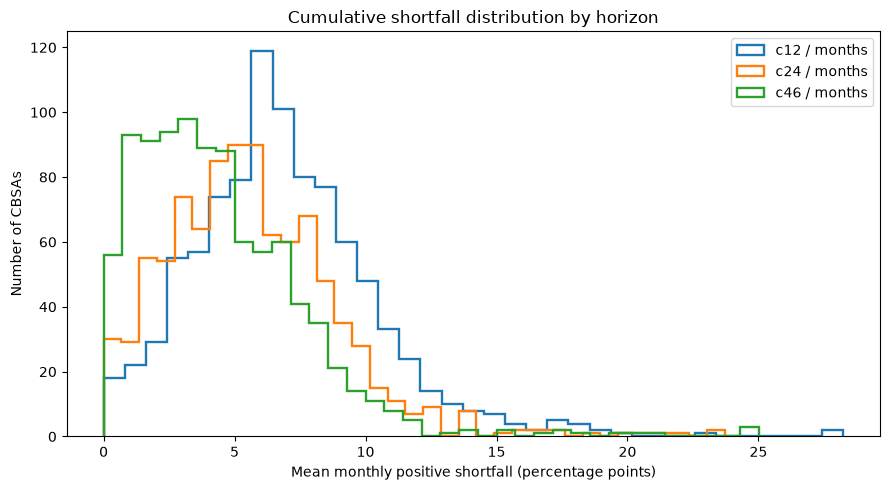

In [3]:
TARGETS={
    'resistance':'resistance_shortfall_pct_aprjun2020',
    'recovery':'recovery_gain_from_trough_pp',
    'persistence':'persistence_shortfall_pct_octdec2023',
    'c12':'cumulative_shortfall_12_pp_months',
    'c24':'cumulative_shortfall_24_pp_months',
    'c46':'cumulative_shortfall_46_pp_months',
}
if INCLUDE_HISTORICAL_STRESS:
    origins=s2meta.get('historical_stress_origins',[])
    if not origins:
        raise ValueError('Stage 1 historical stress targets absent: rerun 01 with RL_STAGE1_LONG_CV=1, then 03')
    for origin in origins:
        key='stress_'+origin
        col=f'cumulative_shortfall_46_pp_months_stress_{origin}'
        if col not in df or df[col].isna().any():
            raise ValueError(f'Missing historical stress target {col}; rerun notebook 03')
        TARGETS[key]=col
    print('Nested geographic CV will be repeated for all 46-month stress targets:',origins)
SIGNED_SOURCE=PROC/'stage2_omb2018_monthly_gaps.csv'
if INCLUDE_SIGNED_46 and SIGNED_SOURCE.exists():
    monthly=pd.read_csv(SIGNED_SOURCE,dtype={'cbsa_code':'string'},parse_dates=['date'])
    monthly.cbsa_code=monthly.cbsa_code.str.zfill(5)
    assert monthly.groupby('cbsa_code').size().eq(46).all(), 'Incomplete monthly gaps'
    if 'gap_pct' not in monthly:
        monthly['gap_pct']=100*(monthly.employment/monthly.counterfactual_employment-1)
    if not monthly.gap_pct.notna().all(): raise ValueError('Missing monthly gaps')
    # Signed deficit can be negative if surpluses outweigh deficits.
    signed=-monthly.groupby('cbsa_code').gap_pct.sum().rename('signed_cumulative_gap_46_pp_months')
    df=df.merge(signed,on='cbsa_code',how='left',validate='one_to_one')
    TARGETS['signed46']='signed_cumulative_gap_46_pp_months'
    # Ensure that 46-month positive shortfall agrees with the earlier stage.
    check=monthly.assign(positive_shortfall=(-monthly.gap_pct).clip(lower=0))                 .groupby('cbsa_code').positive_shortfall.sum()
    reference=outcomes.set_index('cbsa_code')['cumulative_shortfall_46_pp_months']
    assert np.allclose(check.loc[reference.index],reference,rtol=1e-5,atol=1e-5), \
        'Stage 03 positive cumulative outcome differs from cached monthly series'
elif INCLUDE_SIGNED_46:
    print('Signed gap sensitivity skipped: stage2_omb2018_monthly_gaps.csv unavailable.')

for key,col in TARGETS.items():
    df[col]=pd.to_numeric(df[col],errors='coerce')
    if df[col].isna().any():raise ValueError(f'Missing target {col}')
    if key not in ('signed46','recovery') and (df[col]<0).any():raise ValueError('Positive deficit/resistance measure cannot be negative')
for a,b in [('c12','c24'),('c24','c46')]:
    if (df[TARGETS[a]]>df[TARGETS[b]]+1e-6).any():
        raise ValueError('Positive cumulative shortfall must be nondecreasing with horizon')

rows=[]
for key,col in TARGETS.items():
    s=df[col]
    rows.append({'target':key,'n':len(s),'mean':s.mean(),'median':s.median(),
                 'p90':s.quantile(.9),'p99':s.quantile(.99),'max':s.max(),
                 'skew':s.skew()})
describe=pd.DataFrame(rows)
describe.to_csv(OUT/(PREFIX+'target_distributions.csv'),index=False)
display(describe.round(2))
fig,ax=plt.subplots(figsize=(9,5))
for k in ('c12','c24','c46'):
    ax.hist(df[TARGETS[k]]/int(k[-2:]),bins=35,histtype='step',linewidth=1.7,
            label=k+' / months')
ax.set(xlabel='Mean monthly positive shortfall (percentage points)',ylabel='Number of CBSAs',
       title='Cumulative shortfall distribution by horizon')
ax.legend();fig.tight_layout()
fig.savefig(OUT/(PREFIX+'horizon_distributions.png'),dpi=170)
plt.show()

## 3. Fold-safe preprocessing and candidate models

- **Ridge coefficient audit:** Ridge winners report imputer-transformed feature names, including missingness indicators, separately for each outer fold. The target scale is logged for transformed-target Ridge; these are predictive associations, not causal effects.
- **Median benchmark:** fixed training-sample median, chosen as the MAE-oriented no-feature baseline; we also report the training mean.
- **Ridge:** standardize predictors, tune the penalty only within training divisions.
- **Log-Ridge:** fit `log1p(cumulative shortfall)` and transform predictions back to the original units; evaluate MAE on the original scale to prevent artificial gains from changing units. Not used for signed (potentially negative) gaps.
- **Nonlinear model:** small, predeclared histogram-gradient-boosting grid with absolute-error loss to capture nonlinearities and reduce sensitivity to extreme outcomes.

**Important:** The 50% variable coverage threshold is re-learned *inside each fitted fold*, not on the full sample. Unpublished nonexistent QCEW industry cells are structural zeros; explicit `N` disclosure suppressions remain missing.

In [4]:
class CoverageSelector(BaseEstimator,TransformerMixin):
    def __init__(self,min_coverage=.50): self.min_coverage=min_coverage
    def fit(self,X,y=None):
        if not isinstance(X,pd.DataFrame):raise TypeError('Expected DataFrame with feature names')
        available=X.notna().mean()
        # Check both missing-value coverage and constant features using ONLY
        # this training fold. Keeps baseline as fallback if nothing qualifies.
        varying=X.nunique(dropna=True).gt(1)
        self.cols_=available.index[(available>=self.min_coverage)&varying].tolist()
        if not self.cols_:
            raise ValueError('No features meet the training-fold coverage threshold')
        return self
    def transform(self,X):
        return X.loc[:,self.cols_].astype(float)

def plus0_inverse(z):
    return np.maximum(0,np.expm1(z))

def score_positive_mae(estimator,X,y):
    return -float(mean_absolute_error(y,np.maximum(0,np.asarray(estimator.predict(X)).ravel())))

def score_signed_mae(estimator,X,y):
    return -float(mean_absolute_error(y,np.asarray(estimator.predict(X)).ravel()))

def ridge_pipeline():
    return Pipeline([
        ('coverage',CoverageSelector(MIN_FEATURE_COVERAGE)),
        ('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scale',StandardScaler()),
        ('model',Ridge())])

def hgb_pipeline():
    # HistGradientBoosting handles NaNs natively; do not need median imputation.
    return Pipeline([
        ('coverage',CoverageSelector(MIN_FEATURE_COVERAGE)),
        ('model',HistGradientBoostingRegressor(
            loss='absolute_error',learning_rate=.05,max_iter=160,
            min_samples_leaf=20,early_stopping=False,random_state=SEED))])

def candidates(target_key):
    items=[]
    for features in ('core','industry','combined'):
        items.append((f'ridge_{features}',features,ridge_pipeline(),
                      {'model__alpha':[.1,1.0,10.0,100.0,1000.0,10000.0,100000.0]}))
    if target_key not in ('signed46','recovery'):
        items.append(('log_ridge_combined','combined',TransformedTargetRegressor(
            regressor=ridge_pipeline(),func=np.log1p,
            inverse_func=plus0_inverse,check_inverse=False),
            {'regressor__model__alpha':[.1,1.0,10.0,100.0,1000.0,10000.0,100000.0]}))
    if ENABLE_HGB:
        items.append(('hgb_combined','combined',hgb_pipeline(),
                      {'model__max_leaf_nodes':[7,15],
                       'model__l2_regularization':[1.0,10.0]}))
    return items

print('Candidate families:',[n for n,*_ in candidates('cum46')])

Candidate families: ['ridge_core', 'ridge_industry', 'ridge_combined', 'log_ridge_combined', 'hgb_combined']


## 4. Nested leave-one-division-out evaluation

The **outer division** is never used to choose the model or the hyperparameters. For each outer split, an inner 4-fold GroupKFold among *training divisions* chooses among the benchmark, feature sets, model families, and their hyperparameters using mean absolute error. The preselected winner makes one prediction for each untouched outer CBSA.

`MAX_OUTER_DIVISIONS=2` is intended **only for testing execution**, not for research conclusions. Set it to `0` for the full result. `ENABLE_HGB=False` can speed up initial benchmarking but changes the candidate set; report the setting used.

In [5]:
from sklearn.base import clone

def metrics(y,p):
    y=np.asarray(y,dtype=float).ravel()
    p=np.asarray(p,dtype=float).ravel()
    return {'mae':float(mean_absolute_error(y,p)),
            'rmse':float(np.sqrt(mean_squared_error(y,p))),
            'r2':float(r2_score(y,p)) if len(y)>1 else np.nan,
            'bias_pred_minus_actual':float(np.mean(p-y))}

outer=LeaveOneGroupOut()
folds=list(outer.split(df,groups=df.geographic_group))
if MAX_OUTER_DIVISIONS:
    folds=folds[:MAX_OUTER_DIVISIONS]
partial_run=MAX_OUTER_DIVISIONS>0
prediction_rows,fold_rows,decision_rows,coef_rows,candidate_failures=[],[],[],[],[]
start=time.perf_counter()
for fold_no,(tr_idx,te_idx) in enumerate(folds,1):
    tr=df.iloc[tr_idx].copy()
    te=df.iloc[te_idx].copy()
    held_div=str(te.geographic_group.iloc[0])
    if te.geographic_group.nunique()!=1:
        raise RuntimeError('A test fold mixes Census divisions')
    if held_div in set(tr.geographic_group):
        raise RuntimeError('Geographic leakage')
    inner=GroupKFold(n_splits=min(4,tr.geographic_group.nunique()))
    print(f'Outer fold {fold_no}/{len(folds)}: {held_div}, train={len(tr)}, test={len(te)}',flush=True)
    for target_key,target_col in TARGETS.items():
        ytr=tr[target_col].to_numpy(dtype=float)
        yte=te[target_col].to_numpy(dtype=float)
        signed=target_key in ('signed46','recovery')
        scorer=score_signed_mae if signed else score_positive_mae
        x_dummy=pd.DataFrame({'constant':np.ones(len(tr))},index=tr.index)
        with threadpool_limits(limits=1):
            median_cv=-float(cross_val_score(
                DummyRegressor(strategy='median'),x_dummy,ytr,groups=tr.geographic_group,
                cv=inner,scoring=scorer,n_jobs=1).mean())
        winner={'name':'training_median','features':'none','inner_cv_mae':median_cv,
                'params':{},'search':None}
        decision_rows.append({'outer_division':held_div,'target':target_key,
                              'candidate':'training_median','feature_set':'none',
                              'inner_cv_mae':median_cv,'best_params':'{}'})
        for name,feature_set,estimator,param_grid in candidates(target_key):
            gs=GridSearchCV(estimator,param_grid,cv=inner,scoring=scorer,
                            n_jobs=N_JOBS,refit=True,error_score='raise')
            try:
                with threadpool_limits(limits=1):
                    gs.fit(tr[FEATURE_SETS[feature_set]],ytr,groups=tr.geographic_group)
                cv_mae=-float(gs.best_score_)
                if not np.isfinite(cv_mae):
                    raise ValueError('Candidate produced a non-finite inner-CV MAE')
            except Exception as exc:
                # Keep the training-only median benchmark in competition. A
                # failed optional model is NOT a reason to discard a division.
                candidate_failures.append({'outer_division':held_div,
                    'target':target_key,'candidate':name,'feature_set':feature_set,
                    'error':f'{type(exc).__name__}: {exc}'})
                print('  AUDIT: candidate failed:',held_div,target_key,name,
                      type(exc).__name__,str(exc)[:160],flush=True)
                continue
            decision_rows.append({'outer_division':held_div,'target':target_key,
                                  'candidate':name,'feature_set':feature_set,
                                  'inner_cv_mae':cv_mae,'best_params':json.dumps(gs.best_params_)})
            if cv_mae < winner['inner_cv_mae']-1e-10:
                winner={'name':name,'features':feature_set,'inner_cv_mae':cv_mae,
                        'params':gs.best_params_,'search':gs}
        mean_pred=np.full(len(te),float(ytr.mean()))
        med_pred=np.full(len(te),float(np.median(ytr)))
        if winner['search'] is None:
            pred_hat=med_pred.copy()
        else:
            pred_hat=np.asarray(winner['search'].predict(
                te[FEATURE_SETS[winner['features']]]),dtype=float).ravel()
        if not signed:pred_hat=np.maximum(0,pred_hat)
        # Interpret Ridge coefficients with their *transformed* design-matrix
        # names. add_indicator=True can add missing-indicator columns and
        # coefficients cannot safely be zipped to the original feature list.
        if winner['search'] is not None:
            best=winner['search'].best_estimator_
            transformed_target=isinstance(best,TransformedTargetRegressor)
            fitted_pipe=best.regressor_ if transformed_target else best
            if (isinstance(fitted_pipe,Pipeline) and
                    isinstance(fitted_pipe.named_steps.get('model'),Ridge)):
                selected_columns=fitted_pipe.named_steps['coverage'].cols_
                imputer=fitted_pipe.named_steps['impute']
                transformed_names=list(imputer.get_feature_names_out(selected_columns))
                b=np.asarray(fitted_pipe.named_steps['model'].coef_,dtype=float).ravel()
                if len(transformed_names)!=len(b):
                    raise ValueError('Ridge coefficient count differs from imputed/indicator feature names')
                for name,value in zip(transformed_names,b):
                    coef_rows.append({'outer_division':held_div,'target':target_key,
                        'model':winner['name'],'feature_set':winner['features'],
                        'transformed_feature':name,'standardized_coefficient':float(value),
                        'is_missingness_indicator':name.startswith('missingindicator_'),
                        'target_scale':'log1p' if transformed_target else 'original'})
        model_metrics=metrics(yte,pred_hat)
        mean_metrics=metrics(yte,mean_pred)
        train_mean_oos_r2=1-float(np.sum((yte-pred_hat)**2))/float(np.sum((yte-mean_pred)**2)) \
            if np.sum((yte-mean_pred)**2)>0 else np.nan
        med_metrics=metrics(yte,med_pred)
        fold_rows.append({
            'outer_division':held_div,'target':target_key,'n_test':len(te),
            'winner':winner['name'],'feature_set':winner['features'],
            'winner_inner_cv_mae':winner['inner_cv_mae'],
            'oos_r2_vs_training_mean':train_mean_oos_r2,
            'winner_best_params':json.dumps(winner['params']),
            **model_metrics,'mean_baseline_mae':mean_metrics['mae'],
            'median_baseline_mae':med_metrics['mae'],
            'skill_vs_mean_pct':100*(1-model_metrics['mae']/mean_metrics['mae']) if mean_metrics['mae']>0 else np.nan,
            'skill_vs_median_pct':100*(1-model_metrics['mae']/med_metrics['mae']) if med_metrics['mae']>0 else np.nan})
        for cbsa,actual,estimate,bmean,bmedian in zip(
                te.cbsa_code,yte,pred_hat,mean_pred,med_pred):
            prediction_rows.append({
                'cbsa_code':str(cbsa),'outer_division':held_div,
                'target':target_key,'observed':float(actual),'predicted':float(estimate),
                'baseline_mean':float(bmean),'baseline_median':float(bmedian),
                'winner':winner['name'],'feature_set':winner['features'],
                'prepandemic_employment_weight':float(te.loc[te.cbsa_code.eq(cbsa),'qcew2019q2_employment'].iloc[0])})
    print('  Completed:',held_div,'elapsed minutes:',round((time.perf_counter()-start)/60,1),flush=True)
    # Checkpoints ensure partial progress survives a notebook interruption.
    pd.DataFrame(prediction_rows).to_csv(OUT/(PREFIX+'nested_predictions_PARTIAL.csv'),index=False)
    pd.DataFrame(fold_rows).to_csv(OUT/(PREFIX+'outer_fold_scores_PARTIAL.csv'),index=False)

predictions=pd.DataFrame(prediction_rows)
fold_scores=pd.DataFrame(fold_rows)
decisions=pd.DataFrame(decision_rows)
outer_coefs=pd.DataFrame(coef_rows,columns=['outer_division','target','model','feature_set',
    'transformed_feature','standardized_coefficient','is_missingness_indicator','target_scale'])
outer_coefs.to_csv(OUT/(PREFIX+'outer_fold_ridge_coefficients'+
                       ('_PARTIAL' if partial_run else '')+'.csv'),index=False)
candidate_failure_audit=pd.DataFrame(candidate_failures,
    columns=['outer_division','target','candidate','feature_set','error'])
candidate_failure_audit.to_csv(OUT/(PREFIX+'candidate_fit_failures'+
                       ('_PARTIAL' if partial_run else '')+'.csv'),index=False)
print('Audited nested-CV candidate failures:',len(candidate_failure_audit))
print('Ridge feature/indicator coefficients:',len(outer_coefs),
      '| missingness-indicator rows:',int(outer_coefs.is_missingness_indicator.sum()))
if not partial_run:
    for key in TARGETS:
        ids=set(predictions.loc[predictions.target.eq(key),'cbsa_code'])
        if len(ids)!=len(df) or ids!=set(df.cbsa_code):
            raise ValueError('Full leave-one-division-out predictions do not cover all CBSAs')
for frame,filename in (
    (predictions,'nested_predictions.csv'),
    (fold_scores,'outer_fold_scores.csv'),
    (decisions,'inner_cv_decisions.csv')):
    suffix='_PARTIAL' if partial_run else ''
    frame.to_csv(OUT/(PREFIX+filename.replace('.csv',suffix+'.csv')),index=False)
print('Nested CV finished; total minutes:',round((time.perf_counter()-start)/60,1))
display(fold_scores.head())

Outer fold 1/10: East North Central, train=775, test=161
  Completed: East North Central elapsed minutes: 0.3
Outer fold 2/10: East South Central, train=841, test=95
  Completed: East South Central elapsed minutes: 0.6
Outer fold 3/10: Middle Atlantic, train=870, test=66
  Completed: Middle Atlantic elapsed minutes: 0.9
Outer fold 4/10: Mountain, train=843, test=93
  Completed: Mountain elapsed minutes: 1.2
Outer fold 5/10: New England, train=910, test=26
  Completed: New England elapsed minutes: 1.6
Outer fold 6/10: Pacific, train=854, test=82
  Completed: Pacific elapsed minutes: 1.9
Outer fold 7/10: Puerto Rico, train=924, test=12
  Completed: Puerto Rico elapsed minutes: 2.2
Outer fold 8/10: South Atlantic, train=785, test=151
  Completed: South Atlantic elapsed minutes: 2.5
Outer fold 9/10: West North Central, train=816, test=120
  Completed: West North Central elapsed minutes: 2.8
Outer fold 10/10: West South Central, train=806, test=130
  Completed: West South Central elapsed mi

,outer_division,target,n_test,winner,feature_set,winner_inner_cv_mae,oos_r2_vs_training_mean,winner_best_params,mae,rmse,r2,bias_pred_minus_actual,mean_baseline_mae,median_baseline_mae,skill_vs_mean_pct,skill_vs_median_pct
0,East North Central,resistance,161,hgb_combined,combined,3.086135,-0.006619,"{""model__l2_regularization"": 10.0, ""model__max...",3.343470,4.538000,-0.354419,-2.383382,3.333469,3.585304,-0.300004,6.745160
1,East North Central,recovery,161,ridge_industry,industry,4.575755,-0.002422,"{""model__alpha"": 100.0}",4.793997,6.363874,-0.081214,-2.323357,4.829406,4.950119,0.733204,3.153912
2,East North Central,persistence,161,log_ridge_combined,combined,2.590523,-0.079934,"{""regressor__model__alpha"": 100.0}",2.636883,3.387364,-0.122363,-1.499193,2.663830,2.902233,1.011575,9.142958
3,East North Central,c12,161,hgb_combined,combined,29.624258,-0.127755,"{""model__l2_regularization"": 10.0, ""model__max...",25.163512,32.882662,-0.234406,-8.368481,24.002950,25.435517,-4.835080,1.069390
4,East North Central,c24,161,hgb_combined,combined,57.347572,-0.112606,"{""model__l2_regularization"": 1.0, ""model__max_...",49.603494,63.561441,-0.196252,-15.550155,47.365495,49.946907,-4.724956,0.687556


## 5. Report pooled accuracy, division-level heterogeneity, and uncertainty

The pooled row combines one strictly out-of-division prediction per CBSA. Report both MAE (and improvement over training-only benchmarks) and R². For comparability across horizons, MAE divided by 12/24/46 is expressed as an error in the average monthly shortfall (percentage points), not a new model fit. The interval resamples *divisions* rather than CBSAs, but with only a small number of independent Census divisions (count shown at runtime) it should be treated as an exploratory stability diagnostic.

In [6]:
pooled_rows=[]
for key, s in predictions.groupby('target',sort=False):
    y=s.observed.to_numpy(float)
    p=s.predicted.to_numpy(float)
    bmean=s.baseline_mean.to_numpy(float)
    bmed=s.baseline_median.to_numpy(float)
    chosen=metrics(y,p)
    mae_mean=mean_absolute_error(y,bmean)
    mae_med=mean_absolute_error(y,bmed)
    horizon={'c12':12,'c24':24,'c46':46,'signed46':46}.get(key, 46 if key.startswith('stress_') else None)
    pooled_rows.append({'target':key,'n_cbsa':len(s),'n_divisions':s.outer_division.nunique(),
                        'mae':chosen['mae'],'mae_per_month':chosen['mae']/horizon if horizon else np.nan,
                        'rmse':chosen['rmse'],'r2':chosen['r2'],
                         'oos_r2_vs_training_mean':1-float(np.sum((y-p)**2))/float(np.sum((y-bmean)**2))
                         if np.sum((y-bmean)**2)>0 else np.nan,
                         'median_fold_r2':float(fold_scores.loc[fold_scores.target.eq(key),'r2'].median()),
                         'median_fold_oos_r2':float(fold_scores.loc[fold_scores.target.eq(key),'oos_r2_vs_training_mean'].median()),
                        'bias_pred_minus_actual':chosen['bias_pred_minus_actual'],
                        'baseline_mean_mae':mae_mean,'baseline_median_mae':mae_med,
                        'skill_vs_mean_pct':100*(1-chosen['mae']/mae_mean) if mae_mean>0 else np.nan,
                        'skill_vs_median_pct':100*(1-chosen['mae']/mae_med) if mae_med>0 else np.nan,
                        'median_division_skill_pct':float(fold_scores.loc[fold_scores.target.eq(key),'skill_vs_median_pct'].median())})
pooled=pd.DataFrame(pooled_rows)
suffix='_PARTIAL' if partial_run else ''
pooled.to_csv(OUT/(PREFIX+'pooled_scores'+suffix+'.csv'),index=False)
selection=(fold_scores.groupby(['target','winner','feature_set'],as_index=False)
           .agg(outer_divisions_selected=('outer_division','size')))
selection.to_csv(OUT/(PREFIX+'selection_counts'+suffix+'.csv'),index=False)
print('Pooled performance (partial smoke test)' if partial_run else 'Pooled nested geographic CV performance')
display(pooled.round(3))
display(selection.sort_values(['target','outer_divisions_selected'],ascending=[True,False]))

# Cluster bootstrap of paired improvement, using a region-weighted MAE. 
# It is descriptive due to the small number of Census divisions.
rng=np.random.default_rng(SEED)
boot_rows=[]
for key,s in predictions.groupby('target'):
    d=list(s.outer_division.unique())
    grouped={g:s.loc[s.outer_division.eq(g)] for g in d}
    if len(d)<4:continue
    diffs=[]
    for _ in range(BOOTSTRAP_REPS):
        sampled=rng.choice(d,size=len(d),replace=True)
        errors=np.concatenate([np.abs(grouped[g].observed.values-grouped[g].predicted.values) for g in sampled])
        baselines=np.concatenate([np.abs(grouped[g].observed.values-grouped[g].baseline_median.values) for g in sampled])
        diffs.append(np.mean(baselines)-np.mean(errors))
    boot_rows.append({'target':key,'mae_advantage_over_median_pp_months':float(np.mean(np.abs(s.observed.values-s.baseline_median.values))-
                                                         np.mean(np.abs(s.observed.values-s.predicted.values))),
                       'bootstrap_mean_advantage_pp_months':float(np.mean(diffs)),
                      'bootstrap_p2_5':float(np.quantile(diffs,.025)),
                      'bootstrap_p97_5':float(np.quantile(diffs,.975)),
                      'n_divisions':len(d)})
boot=pd.DataFrame(boot_rows,columns=['target','mae_advantage_over_median_pp_months',
                                    'bootstrap_mean_advantage_pp_months','bootstrap_p2_5','bootstrap_p97_5','n_divisions'])
boot.to_csv(OUT/(PREFIX+'division_bootstrap'+suffix+'.csv'),index=False)
if not boot.empty:display(boot.round(3))
# Employment-weighted **sensitivity only**: size weights are measured before 2020.
weighted_rows=[]
for key,s in predictions.groupby('target'):
    w=s.prepandemic_employment_weight.to_numpy(float)
    if not np.isfinite(w).all() or (w<=0).any():
        raise ValueError('Need positive pre-pandemic covered employment for employment weighting')
    observed=s.observed.to_numpy(float)
    actual_error=np.abs(observed-s.predicted.to_numpy(float))
    median_error=np.abs(observed-s.baseline_median.to_numpy(float))
    weighted_mae=float(np.average(actual_error,weights=w))
    weighted_baseline=float(np.average(median_error,weights=w))
    weighted_rows.append({'target':key,'weighted_mae':weighted_mae,
        'weighted_training_median_mae':weighted_baseline,
        'weighted_skill_vs_median_pct':100*(1-weighted_mae/weighted_baseline) if weighted_baseline>0 else np.nan,
        'weight_definition':'2019 Q2 all-covered QCEW employment'})
weighted=pd.DataFrame(weighted_rows)
weighted.to_csv(OUT/(PREFIX+'employment_weighted_sensitivity'+suffix+'.csv'),index=False)
print('Pre-pandemic employment-weighted MAE sensitivity:')
display(weighted.round(3))


Pooled nested geographic CV performance


,target,n_cbsa,n_divisions,mae,mae_per_month,rmse,r2,oos_r2_vs_training_mean,median_fold_r2,median_fold_oos_r2,bias_pred_minus_actual,baseline_mean_mae,baseline_median_mae,skill_vs_mean_pct,skill_vs_median_pct,median_division_skill_pct
0,resistance,936,10,3.148,NaN,4.206,0.210,0.248,-0.028,0.292,-0.421,3.680,3.666,14.461,14.135,10.240
1,recovery,936,10,4.739,NaN,6.484,0.064,0.082,0.087,0.194,-0.113,4.965,4.921,4.549,3.700,4.728
2,persistence,936,10,2.615,NaN,4.026,-0.073,-0.066,-0.075,-0.080,-1.174,2.854,2.723,8.378,3.989,5.056
3,c12,936,10,29.216,2.435,39.230,0.122,0.144,0.010,0.191,-0.670,31.917,31.759,8.461,8.005,4.997
4,c24,936,10,57.238,2.385,75.779,0.069,0.086,-0.052,0.118,-2.511,59.939,59.763,4.507,4.226,3.423
5,c46,936,10,106.292,2.311,145.766,0.022,0.035,-0.067,0.073,-17.829,111.172,110.159,4.390,3.510,6.714
6,stress_2013_06,936,10,140.739,3.060,182.756,0.030,0.054,-0.062,0.048,-4.056,148.213,147.091,5.043,4.319,3.060
7,stress_2014_06,936,10,145.116,3.155,187.029,-0.093,-0.065,-0.253,-0.052,-20.919,144.915,145.113,-0.139,-0.002,-0.296
8,stress_2014_12,936,10,141.876,3.084,182.194,-0.070,-0.043,-0.237,-0.044,-9.017,142.005,141.805,0.091,-0.050,-2.553
9,signed46,936,10,138.305,3.007,193.885,0.030,0.045,-0.043,0.116,-0.132,142.355,143.270,2.845,3.466,4.583


,target,winner,feature_set,outer_divisions_selected
1,c12,ridge_combined,combined,8
0,c12,hgb_combined,combined,2
2,c24,hgb_combined,combined,6
3,c24,ridge_combined,combined,4
4,c46,hgb_combined,combined,7
6,c46,ridge_combined,combined,2
5,c46,log_ridge_combined,combined,1
8,persistence,log_ridge_combined,combined,8
7,persistence,hgb_combined,combined,2
11,recovery,ridge_industry,industry,7


,target,mae_advantage_over_median_pp_months,bootstrap_mean_advantage_pp_months,bootstrap_p2_5,bootstrap_p97_5,n_divisions
0,c12,2.542,2.699,1.184,5.104,10
1,c24,2.526,2.575,0.915,4.839,10
2,c46,3.867,4.071,-0.556,9.438,10
3,persistence,0.109,0.110,-0.004,0.234,10
4,recovery,0.182,0.178,-0.133,0.450,10
5,resistance,0.518,0.530,0.326,0.828,10
6,signed46,4.965,5.201,-0.105,11.032,10
7,stress_2013_06,6.352,6.441,1.030,13.921,10
8,stress_2014_06,-0.003,0.181,-4.405,5.431,10
9,stress_2014_12,-0.071,0.378,-6.032,10.531,10


Pre-pandemic employment-weighted MAE sensitivity:


,target,weighted_mae,weighted_training_median_mae,weighted_skill_vs_median_pct,weight_definition
0,c12,23.921,34.724,31.111,2019 Q2 all-covered QCEW employment
1,c24,48.563,62.457,22.246,2019 Q2 all-covered QCEW employment
2,c46,89.022,110.812,19.664,2019 Q2 all-covered QCEW employment
3,persistence,2.581,2.848,9.365,2019 Q2 all-covered QCEW employment
4,recovery,3.235,3.127,-3.468,2019 Q2 all-covered QCEW employment
5,resistance,2.650,3.645,27.288,2019 Q2 all-covered QCEW employment
6,signed46,101.142,123.115,17.847,2019 Q2 all-covered QCEW employment
7,stress_2013_06,114.496,141.439,19.049,2019 Q2 all-covered QCEW employment
8,stress_2014_06,113.185,148.345,23.702,2019 Q2 all-covered QCEW employment
9,stress_2014_12,120.422,142.732,15.631,2019 Q2 all-covered QCEW employment


## 6. Visual diagnostics and largest residuals

Large 46-month errors may reflect inherently difficult extrapolation rather than poor fitting of the cross-sectional model alone. Inspect and report the outlying areas; do not delete them just to improve results.

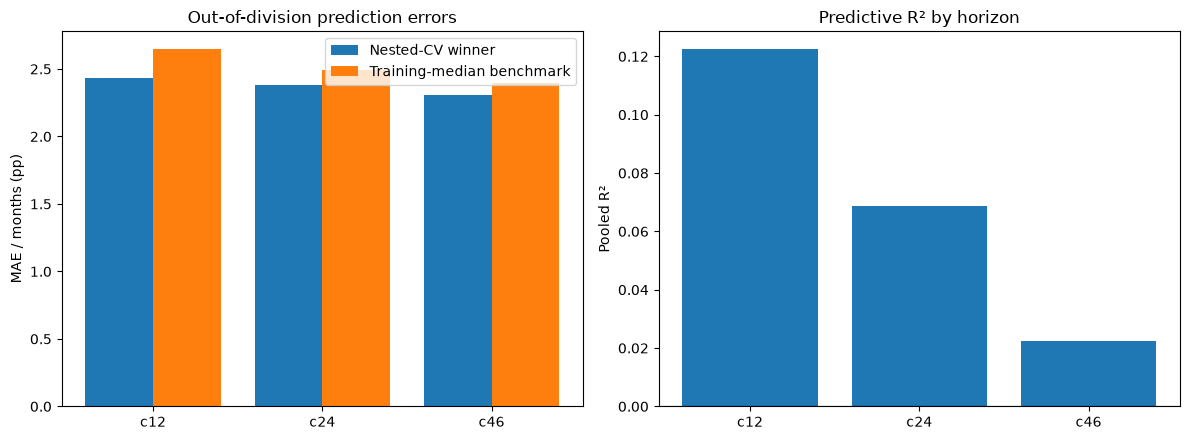

Largest out-of-division residuals (do not remove automatically)


,cbsa_code,outer_division,target,observed,predicted,baseline_mean,baseline_median,winner,feature_set,prepandemic_employment_weight,residual_pred_minus_actual,abs_error
3696,16100,Mountain,c46,1140.699431,200.410174,205.318340,182.084094,hgb_combined,combined,33078.333333,-940.289256,940.289256
8807,37770,West South Central,c46,1117.606055,271.603448,203.137158,182.677978,ridge_combined,combined,7761.000000,-846.002607,846.002607
8730,14300,West South Central,c46,1150.113484,352.901745,203.137158,182.677978,ridge_combined,combined,8490.666667,-797.211740,797.211740
6242,46420,South Atlantic,c46,965.556304,173.272972,205.218841,180.116783,hgb_combined,combined,8422.333333,-792.283332,792.283332
8775,29340,West South Central,c46,770.462160,9.653116,203.137158,182.677978,ridge_combined,combined,112378.000000,-760.809044,760.809044
8839,49820,West South Central,c46,822.287305,119.375896,203.137158,182.677978,ridge_combined,combined,3534.000000,-702.911409,702.911409
4848,28180,Pacific,c46,922.812101,241.664573,197.966645,172.434539,hgb_combined,combined,34068.666667,-681.147529,681.147529
6233,44900,South Atlantic,c46,795.235742,141.155551,205.218841,180.116783,hgb_combined,combined,6055.333333,-654.080191,654.080191
2944,42900,Middle Atlantic,c46,719.320761,127.579387,195.475128,165.893302,hgb_combined,combined,12702.000000,-591.741374,591.741374
4847,27980,Pacific,c46,805.085768,256.845105,197.966645,172.434539,hgb_combined,combined,80657.000000,-548.240664,548.240664


Nested geographic predictive skill under alternative constructed counterfactuals:


,target,mae_per_month,r2,oos_r2_vs_training_mean,skill_vs_median_pct
5,c46,2.311,0.022,0.035,3.510
6,stress_2013_06,3.060,0.030,0.054,4.319
7,stress_2014_06,3.155,-0.093,-0.065,-0.002
8,stress_2014_12,3.084,-0.070,-0.043,-0.050


These are 3 historical-error stress paths, NOT calibrated confidence intervals.
Sensitivity of constructed 46-month outcomes (not a separate geographic model evaluation):


,scenario,mean_original_c46,mean_alternative_c46,median_difference_pp_months,spearman_rank_correlation
0,ensemble,202.327,171.23,-15.871,0.913
1,damped,202.327,168.27,-15.939,0.895


... (3 outputs left out)

,model,n_cbsa,median_monthly_shortfall_pp,mean_monthly_shortfall_pp
0,ets,480,3.669,4.167
1,sarima,304,3.911,4.712
2,seasonal_drift,70,4.171,4.669
3,seasonal_naive,32,3.593,3.796
4,trend_seasonal,50,4.671,4.714


Pre-pandemic growth vs constructed resilience target (diagnostic, not identification):


,outcome,spearman_growth_correlation
0,cumulative_shortfall_46_pp_months,0.122
1,cumulative_shortfall_46_pp_months_ensemble,-0.148
2,cumulative_shortfall_46_pp_months_damped,-0.167


Top 30 c46 CBSA codes saved; verify area names against the September 2018 OMB delineation.


In [7]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
seq=[k for k in ('c12','c24','c46') if k in set(pooled.target)]
bar=pooled.set_index('target').loc[seq]
xs=np.arange(len(seq))
axs[0].bar(xs-.20,bar.mae_per_month.to_numpy()/1, width=.4,label='Nested-CV winner')
axs[0].bar(xs+.20,np.array([bar.loc[k,'baseline_median_mae']/int(k[-2:]) for k in seq]),
           width=.4,label='Training-median benchmark')
axs[0].set(xticks=xs,xticklabels=seq,ylabel='MAE / months (pp)',
           title='Out-of-division prediction errors')
axs[0].legend()
axs[1].bar(seq,bar.r2.values)
axs[1].axhline(0,color='black',linewidth=.8)
axs[1].set(ylabel='Pooled R²',title='Predictive R² by horizon')
fig.tight_layout();fig.savefig(OUT/(PREFIX+'geographic_comparison.png'),dpi=170)
plt.show()

resids=predictions.copy()
resids['residual_pred_minus_actual']=resids.predicted-resids.observed
resids['abs_error']=resids.residual_pred_minus_actual.abs()
worst=(resids.sort_values('abs_error',ascending=False)
       .groupby('target',group_keys=False).head(20))
worst.to_csv(OUT/(PREFIX+'largest_residuals'+suffix+'.csv'),index=False)
print('Largest out-of-division residuals (do not remove automatically)')
display(worst.loc[worst.target.eq('c46')].head(10))
# Counterfactual uncertainty carried into Stage 2: optional rerun of the
# entire nested geographic CV on each 54-month historical stress path.
if INCLUDE_HISTORICAL_STRESS:
    sensitivity=pooled.loc[pooled.target.isin(['c46']+[k for k in TARGETS if k.startswith('stress_')])].copy()
    sensitivity.to_csv(OUT/(PREFIX+'historical_stress_geographic_scores'+suffix+'.csv'),index=False)
    print('Nested geographic predictive skill under alternative constructed counterfactuals:')
    display(sensitivity[['target','mae_per_month','r2','oos_r2_vs_training_mean','skill_vs_median_pct']].round(3))
    print('These are 3 historical-error stress paths, NOT calibrated confidence intervals.')
# Compare original c46 with counterfactual scenarios; descriptive target robustness only.
scenario_rows=[]
for name in ('ensemble','damped'):
    alt=f'cumulative_shortfall_46_pp_months_{name}'
    if alt not in df:continue
    x=df[TARGETS['c46']].to_numpy(float)
    z=df[alt].to_numpy(float)
    scenario_rows.append(dict(scenario=name,mean_original_c46=float(np.mean(x)),
        mean_alternative_c46=float(np.mean(z)),median_difference_pp_months=float(np.median(z-x)),
        spearman_rank_correlation=float(pd.Series(x).corr(pd.Series(z),method='spearman'))))
if scenario_rows:
    scenario_df=pd.DataFrame(scenario_rows)
    scenario_df.to_csv(OUT/(PREFIX+'counterfactual_scenario_outcomes'+suffix+'.csv'),index=False)
    print('Sensitivity of constructed 46-month outcomes (not a separate geographic model evaluation):')
    display(scenario_df.round(3))
# Re-evaluate the stated strengthening criteria explicitly, without choosing the best outcome post hoc.
criteria=[]
for _,r in pooled.iterrows():
    b=boot.loc[boot.target.eq(r.target)]
    ci_ok=bool(len(b) and b.iloc[0].bootstrap_p2_5>0)
    fr=fold_scores.loc[fold_scores.target.eq(r.target)]
    n_positive=int(fr.skill_vs_median_pct.gt(0).sum())
    criteria.append({'target':r.target,'skill_vs_median_positive':bool(r.skill_vs_median_pct>0),
                     'pooled_oos_r2_vs_train_mean_positive':bool(r.oos_r2_vs_training_mean>0),
                     'positive_skill_in_majority_divisions':bool(n_positive>len(fr)/2),
                     'bootstrap_lower_bound_positive':ci_ok,
                     'meets_all_criteria':bool(r.skill_vs_median_pct>0 and
                                               r.oos_r2_vs_training_mean>0 and
                                               n_positive>len(fr)/2 and ci_ok)})
criteria_df=pd.DataFrame(criteria)
criteria_df.to_csv(OUT/(PREFIX+'strength_criteria'+suffix+'.csv'),index=False)
print('Predeclared strengthening criteria (exploratory with few independent divisions):')
display(criteria_df)
if 'c46' in set(criteria_df.target):
    if not bool(criteria_df.set_index('target').loc['c46','meets_all_criteria']):
        print('Conclusion: the primary 46-month target does NOT meet all strengthening criteria; report weak/uncertain long-horizon predictability.')
    else:
        print('Conclusion: the primary 46-month target passes the prespecified diagnostics; interpret conservatively.')

# Mechanically induced trend associations and selected Stage 1 model-family audit.
selected_path=OUT/'stage1_omb2018_selected_models.csv'
if sha256(selected_path)!=s1meta['selected_models_sha256']:
    raise ValueError('Selected Stage 1 model family file has changed since its manifest')
selected_meta=pd.read_csv(selected_path,dtype={'cbsa_code':'string'})
selected_meta.cbsa_code=selected_meta.cbsa_code.str.zfill(5)
family_audit=df[['cbsa_code',TARGETS['c46'],'qcew2018to2019q2_growth']].merge(
    selected_meta[['cbsa_code','model','specification']],on='cbsa_code',how='left',
    validate='one_to_one')
if family_audit.model.isna().any():
    raise ValueError('Missing Stage 1 selected family for CBSA')
family_audit['mean_monthly_c46_shortfall_pp']=family_audit[TARGETS['c46']]/46
family_summary=family_audit.groupby('model').agg(
    n_cbsa=('cbsa_code','size'),median_monthly_shortfall_pp=('mean_monthly_c46_shortfall_pp','median'),
    mean_monthly_shortfall_pp=('mean_monthly_c46_shortfall_pp','mean')).reset_index()
family_summary.to_csv(OUT/(PREFIX+'c46_by_stage1_family'+suffix+'.csv'),index=False)
print('Primary outcome by selected counterfactual model family:')
display(family_summary.round(3))
# This is a descriptive test of possible mechanical trend dependence, not causal evidence.
growth_correlations=[]
for variable in [TARGETS['c46'],'cumulative_shortfall_46_pp_months_ensemble',
                 'cumulative_shortfall_46_pp_months_damped']:
    if variable in df:
        growth_correlations.append({'outcome':variable,
            'spearman_growth_correlation':float(df['qcew2018to2019q2_growth'].corr(
                df[variable],method='spearman'))})
growth_audit=pd.DataFrame(growth_correlations)
growth_audit.to_csv(OUT/(PREFIX+'pretrend_outcome_association'+suffix+'.csv'),index=False)
print('Pre-pandemic growth vs constructed resilience target (diagnostic, not identification):')
display(growth_audit.round(3))
family_audit.nlargest(30,'mean_monthly_c46_shortfall_pp').to_csv(
    OUT/(PREFIX+'highest_c46_cbsa_codes'+suffix+'.csv'),index=False)
print('Top 30 c46 CBSA codes saved; verify area names against the September 2018 OMB delineation.')


## 7. Audit manifest and interpretation checklist

**A stronger result** means genuine improvement against the training-only median benchmark across multiple held-out divisions, with a positive pooled R² and an uncertainty interval that does not suggest severe instability. If this fails for 46 months, report the weak predictability rather than replacing the original outcome. If 12 or 24 months performs better, present that as evidence that the pre-pandemic structural predictors are more informative for *nearer-term* cumulative deficits.

Possible substantive reasons for weak 46-month predictability: policy and health developments after 2020, regional demand shifts, migration, structural breaks, and large forecast uncertainty at horizons exceeding four years. These explanations are **hypotheses** and cannot be established from forecast residuals alone.

The original shortfall metric truncates surpluses at zero. If the signed 46-month metric was available, compare its model skill and regional rankings as a sensitivity analysis; do not silently replace the original positive-deficit area.

The established criteria are evaluated explicitly in section 6. The 46-month primary result should not be described as strong merely because a pooled R² is slightly positive; inspect division-level R², training-median skill and its division-bootstrap interval. A few independent divisions cannot support a definitive confidence statement.


In [8]:
manifest={
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'pipeline_step':'04 geographic validation of principal resilience and cumulative outcomes',
 'geographic_vintage':'2018-09','stage2_information_cutoff':'2020-02-29',
 'stage1_training_cutoff':'2019-06-01',
 'predictor_sha256':sha256(p_path),'outcomes_sha256':sha256(o_path),
 'outcomes':TARGETS,'feature_sets':FEATURE_SETS,
 'historical_stress_geographic_evaluated':INCLUDE_HISTORICAL_STRESS,
 'historical_stress_source_sha256':s2meta.get('historical_stress_outcomes_sha256'),
  'verified_stage2_outcome_sha256':s2meta['resilience_outcomes_sha256'],
  'verified_monthly_gaps_sha256':s2meta['monthly_gaps_sha256'],
  'prediction_file_sha256':sha256(OUT/(PREFIX+'nested_predictions'+suffix+'.csv')),
  'criteria_file_sha256':sha256(OUT/(PREFIX+'strength_criteria'+suffix+'.csv')),
  'employment_weighted_sensitivity_sha256':sha256(OUT/(PREFIX+'employment_weighted_sensitivity'+suffix+'.csv')),
  'outer_fold_ridge_coefficients_sha256':sha256(OUT/(PREFIX+'outer_fold_ridge_coefficients'+suffix+'.csv')),
  'candidate_fit_failures_sha256':sha256(OUT/(PREFIX+'candidate_fit_failures'+suffix+'.csv')),
 'n_geographic_divisions':int(df.geographic_group.nunique()),
 'n_outer_divisions_evaluated':int(len(folds)),
 'partial_smoke_test':bool(partial_run),
 'model_candidates':[name for name,*_ in candidates('cum46')],
 'n_jobs':N_JOBS,'enable_hgb':ENABLE_HGB,'min_feature_coverage':MIN_FEATURE_COVERAGE,
 'inner_cv':'GroupKFold(4) nested within leave-one-Census-division-out',
 'selection_metric':'MAE on original target scale',
 'reported_metrics':'MAE, RMSE, R², mean prediction bias, skill vs training mean and median',
 'sklearn':sklearn.__version__,'python':platform.python_version(),
 'limitations':['2018 delineations do not guarantee historical QCEW as-of publication vintages',
                'Forecast 2019-07 to 2023-12 is a long extrapolation after 2019-Q2',
                'Industry missingness is not random; imputation applies only within training folds',
                'Small number of independent divisions (recorded dynamically); group-bootstrap intervals are descriptive',
                'Outcome associations are predictive and not causal']
}
(OUT/(PREFIX+'manifest'+('_PARTIAL' if partial_run else '')+'.json')).write_text(
    json.dumps(manifest,indent=2))
print('Finished. Output prefix:',OUT/PREFIX)
print('Do not cite PARTIAL smoke-test results as complete national geographic validation.')

Finished. Output prefix: c:\Users\adamt\OneDrive\Documents\Directed Practicum\regional-labor-resilience\output\stage2_geographic04_
Do not cite PARTIAL smoke-test results as complete national geographic validation.
